# CSE 242 – Machine Learning

## Background

This assignment covers the essential mathematical and statistical foundations required for a comprehensive understanding of machine learning. It emphasizes Linear Algebra, Probability theory, Maximum Likelihood Estimation (MLE), Maximum a Posteriori (MAP) estimation, and Principal Component Analysis (PCA). A strong grasp of these mathematical tools is essential for advancing to more sophisticated machine learning topics.

Refer to the following slides provided in class for detailed explanations:

- `Lecture1_intro`
- `Lecture2_review`

## Assignment Objectives

In this assignment, you will:

- Solve detailed problems in Linear Algebra involving vectors, matrices, eigenvectors, and eigenvalues.
- Derive solutions and perform calculations related to Probability, MLE, and MAP estimations.
- Integrate mathematical understanding with practical programming in PCA.

## Grading

Grading will be done by the TA.  The assignment is worth **100 points**, divided as: 20 for linear algebra, 50 for probability and estimation, and 30 for PCA. Please submit the final assignment to Canvas.

# LLM Usage Log as indicated in syllabus
https://claude.ai/share/69d2a2da-2f21-4f03-a576-7275e81d038f

In [61]:
import numpy as np
import matplotlib.pyplot as plt

## Part 3: Principal Component Analysis (Math and Programming) (30 points)

**Q1 (10 points).** Given a dataset represented by a random vector $X$, derive the mathematical expression for the variance of the projection onto a unit vector $u$:

$$
Var(u^TX)=u^T\Sigma u
$$

Document each intermediate mathematical step and define the covariance matrix $\Sigma$.

In [62]:
# PART 3 (30 points), Q1: Define covariance and derive Var(u.T@X)=u.T@Sigma@u.
# YOUR ANSWER HERE
# LOOK AT PDF

**Q2 (5 points).** Generate a synthetic 2-dimensional dataset composed of two correlated Gaussian features. Use NumPy for data generation. Visualize this dataset with scatter plots and discuss the correlation structure observed.

target rho = +0.90, sample rho = +0.899
target rho = +0.00, sample rho = +0.002
target rho = -0.60, sample rho = -0.579


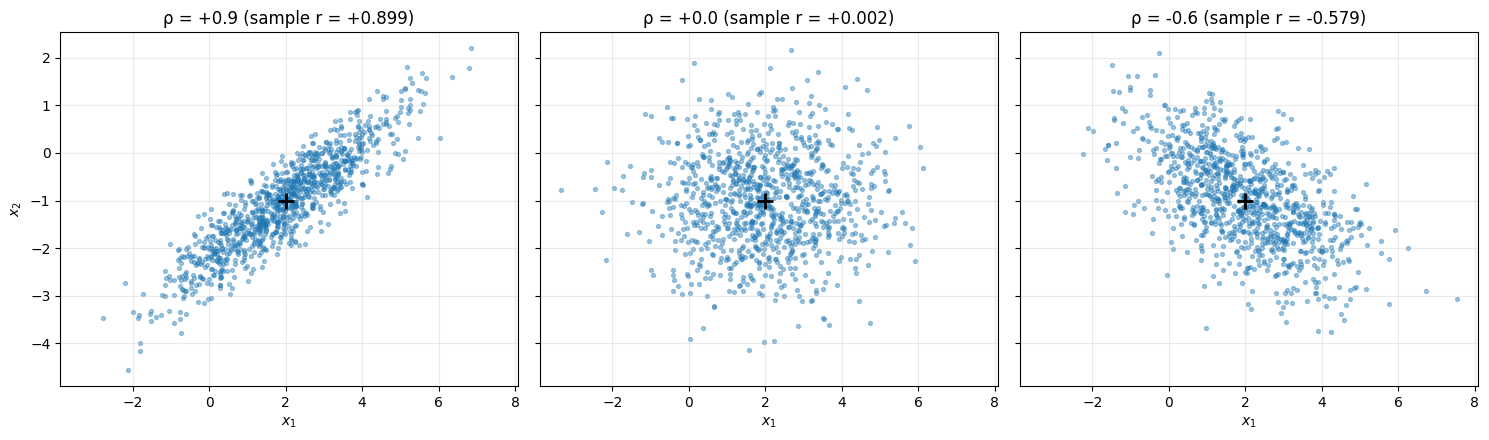

In [63]:
# P3 Q2: Describe the Gaussian generator and observed correlation.
rng = np.random.default_rng(123)
n = 1000

# Mean vector and standard deviations
mu = np.array([2.0, -1.0])
sigma = np.array([1.5, 1])


def make_data(rho):
    """Draw n samples from a bivariate Gaussian with correlation rho."""
    cov = np.array([
        [sigma[0] ** 2, rho * sigma[0] * sigma[1]],
        [rho * sigma[0] * sigma[1], sigma[1] ** 2],
    ])
    return rng.multivariate_normal(mu, cov, size=n), cov


rhos = [0.9, 0.0, -0.6]
data = {}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for ax, rho in zip(axes, rhos):
    X, cov = make_data(rho)
    data[rho] = X
    r = np.corrcoef(X.T)[0, 1]
    print(f"target rho = {rho:+.2f}, sample rho = {r:+.3f}")

    ax.scatter(X[:, 0], X[:, 1], s=8, alpha=0.4)
    ax.plot(*mu, "k+", ms=12, mew=2)
    ax.set_title(f"ρ = {rho:+.1f} (sample r = {r:+.3f})")
    ax.set_xlabel("$x_1$")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("$x_2$")
fig.tight_layout()
plt.show()

From what I see the plots show that the sign of rho sets the tilt of the ellipse (up for +0.9, none for 0, down for −0.6) while its magnitude sets how thin it is, with the sample correlations (0.898, 0.002, −0.580) landing close to their targets apart from sampling noise.

**Q3 (10 points).** Implement PCA from scratch using NumPy. Follow these steps:

- Center your dataset (mean subtraction).
- Compute the covariance matrix.
- Find eigenvalues and eigenvectors of the covariance matrix.
- Select the principal components corresponding to the highest eigenvalues.

Document each step in your implementation, linking it to your mathematical derivation from Q1. Provide visualizations of your original data along with identified principal component directions.

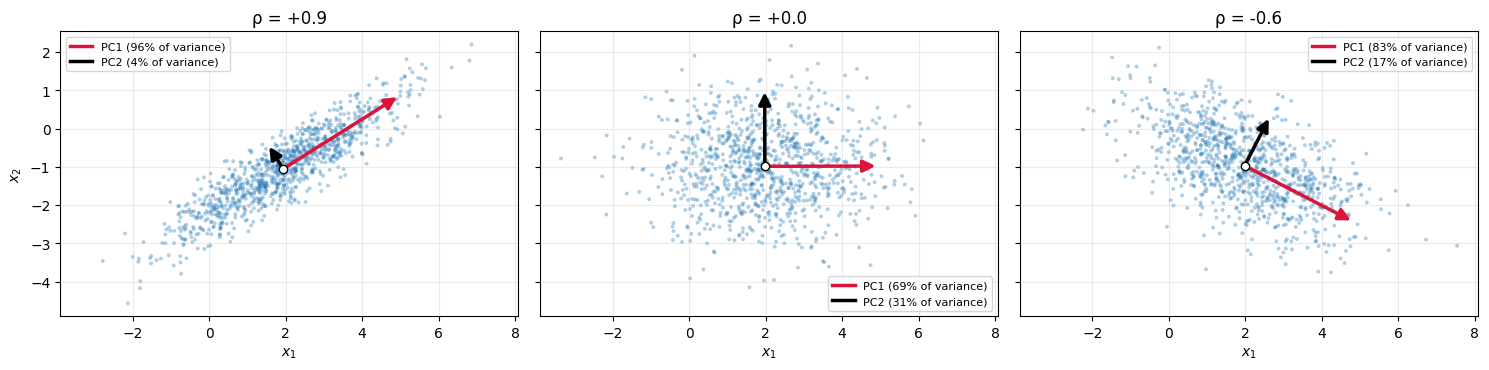

In [64]:
# P3 Q3: Link centering/covariance/eigendecomposition to the derivation and explain the plot.
# YOUR ANSWER HERE
def pca(X, k):
    """
    X : (n_samples, n_features) data matrix
    k : number of principal components to keep
    Returns mean, eigenvalues (descending), eigenvectors (columns),
    top-k components, and projected data.
    """
    n, d = X.shape

    # 1. Center the data
    mean = np.mean(X, axis=0)
    Xc = X - mean

    # 2. Covariance matrix
    cov = Xc.T @ Xc / (n - 1)

    # 3. Eigen-decomposition (eigh works because cov is symmetric)
    eigvals, eigvecs = np.linalg.eigh(cov)

    # 4. Sort from largest to smallest eigenvalue
    order = np.argsort(-eigvals)
    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]

    # 5. Fix sign ambiguity: largest-magnitude entry of each eigenvector is positive
    pivot = np.argmax(np.abs(eigvecs), axis=0)
    signs = np.sign(eigvecs[pivot, np.arange(d)])
    signs[signs == 0] = 1
    eigvecs = eigvecs * signs

    # 6. Keep the first k eigenvectors and project
    components = eigvecs[:, :k]
    Z = Xc @ components

    return mean, eigvals, eigvecs, components, Z


def plot_pca(ax, X, mean, eigvals, components, title=None):
    """X: data, mean: (2,), eigvals: FULL descending vector, components: (2, k) columns."""
    ratio = eigvals / eigvals.sum()
    ax.scatter(X[:, 0], X[:, 1], s=8, alpha=0.35, color="tab:blue", edgecolors="none")

    # Arrows start at the mean; length = 2 standard deviations along each PC
    for i, c in enumerate(["crimson", "black"]):
        tip = mean + 2 * np.sqrt(eigvals[i]) * components[:, i]
        ax.annotate("", xy=tip, xytext=mean,
                    arrowprops=dict(arrowstyle="-|>", color=c, lw=2.5, mutation_scale=18))
        ax.plot([], [], color=c, lw=2.5, label=f"PC{i + 1} ({ratio[i]:.0%} of variance)")
    ax.plot(*mean, "o", color="white", mec="black", ms=6, zorder=5)

    ax.set_title(title)
    ax.set_xlabel("$x_1$")
    ax.set_aspect("equal", adjustable="box")  # keeps PCs visibly orthogonal
    ax.grid(alpha=0.25)
    ax.legend(loc="best", fontsize=8)


# Run PCA on each stored dataset
results = {}
for rho, X in data.items():
    mean, eigvals, eigvecs, components, Z = pca(X, k=2)
    results[rho] = (X, mean, eigvals, components)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharex=True, sharey=True)
for ax, (rho, res) in zip(axes, results.items()):
    plot_pca(ax, *res, title=f"ρ = {rho:+.1f}")
axes[0].set_ylabel("$x_2$")
fig.tight_layout()
plt.show()

**Q4 (10 points).** "Compute the proportion of total variance explained by each principal component. Discuss the results and explain the significance of dimensionality reduction. Provide insights into the trade-off between explained variance and dimensionality reduction."

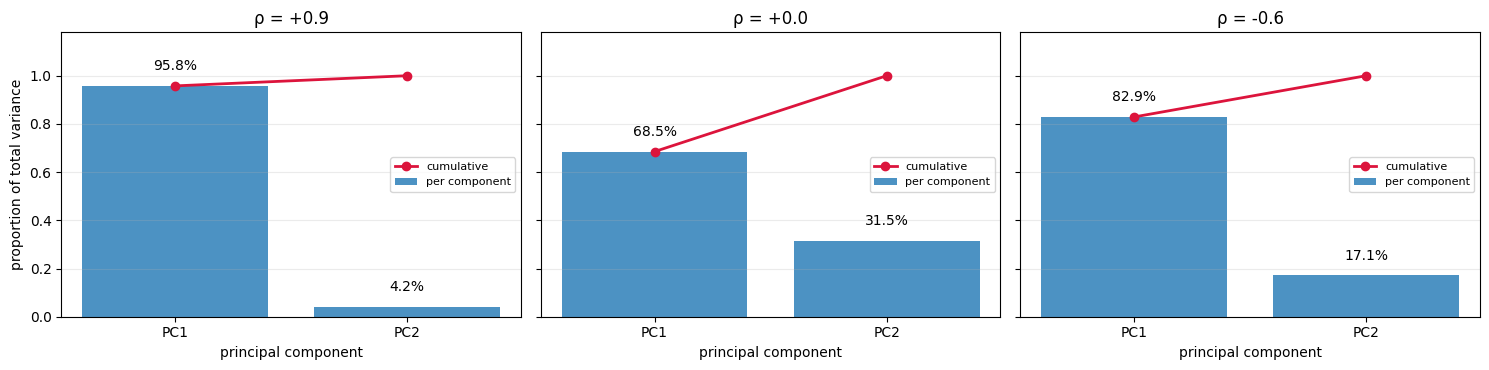

In [65]:
# P3 Q4: Interpret the variance fractions and dimensionality reduction tradeoff.
def explained_variance(eigenvalues):
    """Return same-shape fractions for nonnegative eigenvalues with positive sum."""
    eigenvalues = np.asarray(eigenvalues, dtype=float)
    return eigenvalues / eigenvalues.sum()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, (rho, (X, mean, eigvals, components)) in zip(axes, results.items()):
    frac = explained_variance(eigvals)
    cum = np.cumsum(frac)
    pcs = np.arange(1, len(frac) + 1)

    bars = ax.bar(pcs, frac, color="tab:blue", alpha=0.8, label="per component")
    ax.bar_label(bars, labels=[f"{f:.1%}" for f in frac], padding=9)
    ax.plot(pcs, cum, "o-", color="crimson", lw=2, label="cumulative")

    ax.set_title(f"ρ = {rho:+.1f}")
    ax.set_xlabel("principal component")
    ax.set_xticks(pcs)
    ax.set_xticklabels([f"PC{i}" for i in pcs])
    ax.set_ylim(0, 1.18)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="center right", fontsize=8)
axes[0].set_ylabel("proportion of total variance")
fig.tight_layout()
plt.show()


PCA compresses well when variables are strongly correlated. At rho = +0.9, PC1 alone keeps 95.8% of the variance, so dropping PC2 loses almost nothing, while at rho = 0 PC1 keeps only 68.5% and reduction costs about a third of the information. The trade-off is that each component you discard gives up its share of variance (rho = -0.6 sits in between at 82.9%), so the right number of components depends on how much information loss you can tolerate as discussed in lecture we should consider this before deciding whether to drop a principle component.